# WiFi indoor localization on UJIIndoorLoc — corrected version

Corrected version (2026). This notebook fixes the problems found in our original DSAI3201 course notebook
(`01_original_course_version.ipynb`, April 2025, two-person team).

**Goal.** From one WiFi scan (the signal strength of up to 520 access points), predict
1. the **building** (3 classes),
2. the **floor** (5 classes), and
3. the **position** (longitude, latitude in metres).

**How it is evaluated.**
- All training, tuning and model selection use only `trainingData.csv`, with **group cross-validation**
  (a whole reference location is held out together, so near-identical scans of the same spot cannot sit on both sides).
- The official `validationData.csv` (recorded about 4 months later) is the **final test set**. It is used only in the
  "Final test" section, and every final model is scored on it exactly once.

The notebook runs top to bottom in Google Colab (free CPU runtime) and downloads the data itself.

## 1. Setup

In [1]:
# Find the repo root (the folder with requirements.txt). If the notebook was opened on its own in Colab, clone the repo.
import importlib.util
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/maryam843/wifi-indoor-localization-ujiindoorloc"
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / "wifi-indoor-localization-ujiindoorloc"
    if not ROOT.exists():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)])
sys.path.insert(0, str(ROOT))   # so that the helpers in src/ can be imported

# Install the pinned versions from requirements.txt, only if a package is missing (Colab already has all of them).
REQUIRED = ["pandas", "numpy", "scipy", "sklearn", "xgboost", "tensorflow", "matplotlib", "seaborn"]
missing = [module for module in REQUIRED if importlib.util.find_spec(module) is None]
if missing:
    print("Missing:", missing, "so installing requirements.txt")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import hashlib
import os
import random
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # hide TensorFlow start-up logs

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import xgboost as xgb
import tensorflow as tf

from scipy.stats import randint, uniform, loguniform
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, make_scorer

from src.encoding import NOT_DETECTED, NO_SIGNAL_DBM, encode_not_detected, to_positive
from src.folds import StableGroupKFold, assign_group_folds

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # same Keras results on every run on the same machine
tf.get_logger().setLevel("ERROR")

START_TIME = time.time()
for lib in (np, pd, sklearn, xgb, tf, scipy, matplotlib, sns):
    print(f"{lib.__name__:12s} {lib.__version__}")

numpy        2.1.3
pandas       2.2.3
sklearn      1.6.1
xgboost      3.4.1
tensorflow   2.20.0
scipy        1.16.3
matplotlib   3.10.0
seaborn      0.13.2


In [3]:
# Folders inside the repo root found in the setup cell.
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
for folder in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    folder.mkdir(exist_ok=True)


def save_and_show(fig, name):
    # Always save BEFORE showing (the original notebook did it the other way round and saved blank images).
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved figures/" + name)

## 2. Data

**UJIIndoorLoc** (UCI Machine Learning Repository, dataset #310), licence CC BY 4.0:
<https://archive.ics.uci.edu/dataset/310/ujiindoorloc>

> Torres-Sospedra, J., Montoliu, R., Martínez-Usó, A., Avariento, J. P., Arnau, T. J., Benedito-Bordonau, M., & Huerta, J. (2014).
> UJIIndoorLoc: A new multi-building and multi-floor database for WLAN fingerprint-based indoor localization problems.
> *2014 International Conference on Indoor Positioning and Indoor Navigation (IPIN)*, 261–270.

Three buildings of Universitat Jaume I (Spain), 4–5 floors each, 520 WiFi access points (WAPs).
`trainingData.csv` has 19,937 scans; `validationData.csv` has 1,111 scans taken about 4 months later.

In [4]:
UCI_URL = "https://archive.ics.uci.edu/static/public/310/ujiindoorloc.zip"
TRAIN_CSV = DATA_DIR / "trainingData.csv"
TEST_CSV = DATA_DIR / "validationData.csv"

if not (TRAIN_CSV.exists() and TEST_CSV.exists()):
    zip_path = DATA_DIR / "ujiindoorloc.zip"
    try:
        print("Downloading UJIIndoorLoc from UCI ...")
        urllib.request.urlretrieve(UCI_URL, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            for member in z.namelist():
                if member.endswith(".csv"):
                    (DATA_DIR / Path(member).name).write_bytes(z.read(member))
    except Exception as err:
        print("Automatic download failed:", err)
        print("Please download the zip manually from https://archive.ics.uci.edu/dataset/310/ujiindoorloc,")
        print("unzip it and put trainingData.csv and validationData.csv in the data/ folder, then re-run.")
        raise

train_raw = pd.read_csv(TRAIN_CSV)
test_raw = pd.read_csv(TEST_CSV)   # official validation set = FINAL TEST SET. Not touched until section 7.
print("trainingData.csv  :", train_raw.shape)
print("validationData.csv:", test_raw.shape)

trainingData.csv  : (19937, 529)
validationData.csv: (1111, 529)


## 3. Preprocessing

### What does the value 100 mean?

Each `WAPxxx` column is the signal strength (RSSI) of one access point, in dBm.
Real readings go from **−104 dBm (very weak)** to **0 dBm (very strong)**. The value **100** means
**"this access point was not detected in this scan"**.

- 100 is **not** a real signal. Left as it is, a model would treat it as *stronger than 0 dBm*, the opposite of the truth.
  So our original decision to treat it specially was right.
- The mistake in the original notebook came next: 465 of the 520 access points were dropped, and the missing values
  in the rest were filled with the median/mean. That turns "not detected" into "detected at normal strength",
  which wipes out the most useful information. Which access points you *cannot* hear tells you a lot about where you are.
- **Correct approach used here:** keep all access points and replace 100 with **−105 dBm**, a value just weaker than
  any real reading. "Not detected" then means "signal too weak to measure", which is physically what it is.
  No imputation is needed.

Other steps:
- Only access points that are **never detected in the training file** are dropped (they carry no information).
- Exact duplicate rows are removed from the **training data only**, and so are training scans where no access point was
  detected (they carry no location information). The test set is not changed.
- The only features are the `WAP` columns. TIMESTAMP, SPACEID, BUILDINGID, USERID, PHONEID, RELATIVEPOSITION and the
  coordinates are **never** used as inputs.

In [5]:
WAP_COLS = [c for c in train_raw.columns if c.startswith("WAP")]
real = train_raw[WAP_COLS].to_numpy()
real = real[real != NOT_DETECTED]
print(f"{len(WAP_COLS)} WAP columns; real RSSI readings range from {real.min()} to {real.max()} dBm")
print(f"Share of 'not detected' (100) values in training: {(train_raw[WAP_COLS] == NOT_DETECTED).to_numpy().mean():.1%}")

# encode_not_detected (src/encoding.py) is a fixed rule, nothing is learned from data: 100 -> -105 dBm.
train = encode_not_detected(train_raw, WAP_COLS)
n_dup = train.duplicated().sum()
train = train.drop_duplicates()
n_detected = (train[WAP_COLS] > NO_SIGNAL_DBM).sum(axis=1)
n_empty = int((n_detected == 0).sum())
train = train[n_detected > 0].reset_index(drop=True)

detected_somewhere = (train[WAP_COLS] > NO_SIGNAL_DBM).any()
FEATURES = [c for c in WAP_COLS if detected_somewhere[c]]

print(f"Removed {n_dup} exact duplicate rows and {n_empty} scans with no detected access point (training only).")
print(f"Training rows: {len(train)}")
print(f"Access points never detected in training (dropped): {len(WAP_COLS) - len(FEATURES)}")
print(f"Features used: {len(FEATURES)} WAP columns")

520 WAP columns; real RSSI readings range from -104 to 0 dBm
Share of 'not detected' (100) values in training: 96.5%


Removed 637 exact duplicate rows and 73 scans with no detected access point (training only).
Training rows: 19227
Access points never detected in training (dropped): 55
Features used: 465 WAP columns


In [6]:
# to_positive (src/encoding.py) maps -105 dBm (not detected) -> 0 and 0 dBm (strongest) -> 1 with a fixed formula.
X = train[FEATURES]
y_building = train["BUILDINGID"]
y_floor = train["FLOOR"]
y_pos = train[["LONGITUDE", "LATITUDE"]]

# Groups for cross-validation: one group = one reference location (building + floor + space).
groups = (train["BUILDINGID"].astype(str) + "-" + train["FLOOR"].astype(str) + "-" + train["SPACEID"].astype(str))
print("Number of location groups:", groups.nunique())

Number of location groups: 735


### A note on the coordinates

LONGITUDE and LATITUDE are given in metres in a map projection. From their values they look like
Web Mercator (EPSG:3857) coordinates. The check below converts the latitude value back to degrees.
Distances in Web Mercator are stretched by 1 / cos(latitude), so a "metre" here is a bit larger than a real metre on the ground.
Like most published work on this dataset, all errors below are reported **in the dataset's own units**.

In [7]:
R_EARTH = 6378137.0
lat_deg = np.degrees(np.arctan(np.sinh(train["LATITUDE"].mean() / R_EARTH)))
lon_deg = np.degrees(train["LONGITUDE"].mean() / R_EARTH)
print(f"Mean position: {lat_deg:.3f} N, {lon_deg:.3f} E (a university campus in Castellón, Spain)")
print(f"Web Mercator scale factor at this latitude: {1 / np.cos(np.radians(lat_deg)):.3f} "
      f"(1 dataset unit = {np.cos(np.radians(lat_deg)):.3f} ground metres)")

Mean position: 39.993 N, -0.067 E (a university campus in Castellón, Spain)
Web Mercator scale factor at this latitude: 1.305 (1 dataset unit = 0.766 ground metres)


## 4. Exploratory data analysis (training data only)

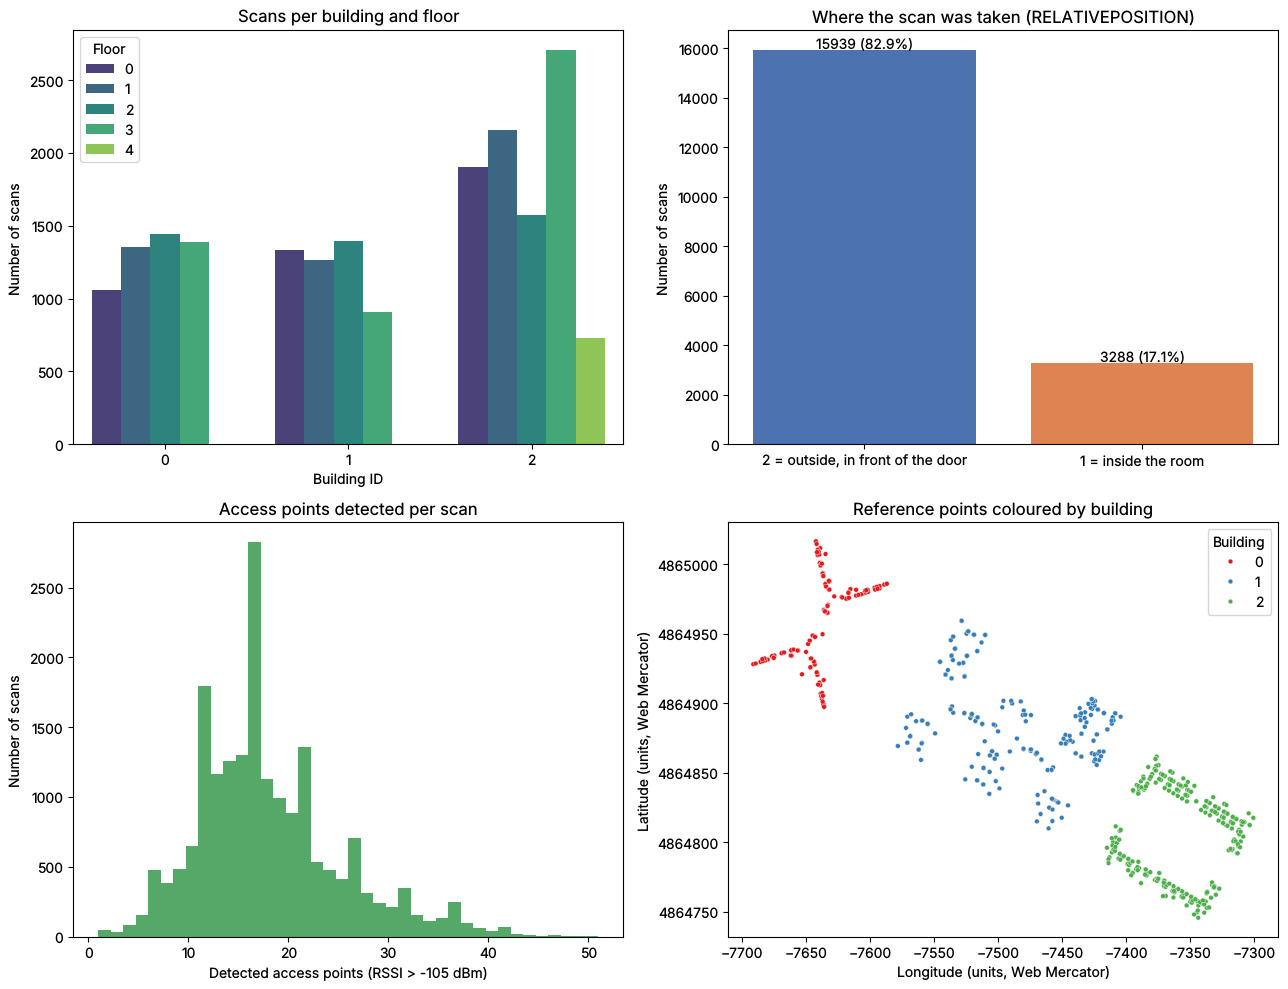

saved figures/eda_overview.png
RELATIVEPOSITION
2 = outside, in front of the door    15939
1 = inside the room                   3288
Median detected access points per scan: 17


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

eda = train.assign(Building=train["BUILDINGID"].astype(str), Floor=train["FLOOR"].astype(str))
sns.countplot(data=eda, x="Building", hue="Floor", order=["0", "1", "2"], hue_order=["0", "1", "2", "3", "4"],
              palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Scans per building and floor")
axes[0, 0].set_xlabel("Building ID")
axes[0, 0].set_ylabel("Number of scans")
axes[0, 0].legend(title="Floor")

# RELATIVEPOSITION: 1 = inside a room, 2 = outside, in front of the door.
rel_labels = {1: "1 = inside the room", 2: "2 = outside, in front of the door"}
rel = train["RELATIVEPOSITION"].map(rel_labels).value_counts()
axes[0, 1].bar(rel.index, rel.values, color=["#4c72b0", "#dd8452"][: len(rel)])
for i, v in enumerate(rel.values):
    axes[0, 1].text(i, v, f"{v} ({v / len(train):.1%})", ha="center", va="bottom")
axes[0, 1].set_title("Where the scan was taken (RELATIVEPOSITION)")
axes[0, 1].set_ylabel("Number of scans")

axes[1, 0].hist(n_detected[n_detected > 0], bins=40, color="#55a868")
axes[1, 0].set_title("Access points detected per scan")
axes[1, 0].set_xlabel("Detected access points (RSSI > -105 dBm)")
axes[1, 0].set_ylabel("Number of scans")

points = eda.drop_duplicates(["LONGITUDE", "LATITUDE"])
sns.scatterplot(data=points, x="LONGITUDE", y="LATITUDE", hue="Building", hue_order=["0", "1", "2"], palette="Set1",
                s=12, ax=axes[1, 1])
axes[1, 1].set_title("Reference points coloured by building")
axes[1, 1].ticklabel_format(useOffset=False, style="plain")
axes[1, 1].set_xlabel("Longitude (units, Web Mercator)")
axes[1, 1].set_ylabel("Latitude (units, Web Mercator)")
axes[1, 1].legend(title="Building")

fig.tight_layout()
save_and_show(fig, "eda_overview.png")

print(rel.to_string())
print(f"Median detected access points per scan: {int(n_detected[n_detected > 0].median())}")

## 5. Evaluation setup

- **Model selection and tuning:** `GroupKFold` on the training file. Group = building-floor-space, so a whole reference
  location is held out together. A random split would put almost identical scans of the same spot into both train
  and test and give over-optimistic scores (this happened in the original notebook).
- **Metrics:** building accuracy; floor accuracy (also called floor hit rate), floor macro-F1, and the share of scans where
  building **and** floor are both right; position error = 2-D Euclidean distance between the true and predicted point,
  summarised by mean, median, 75th and 90th percentile.
- **Final test:** the official validation file, once per final model (section 7).

In [9]:
# StableGroupKFold (src/folds.py) gives the same folds on every machine. sklearn's GroupKFold does not:
# 709 of the 735 groups share their size with another group, and the order of those ties depends on the CPU.
CV = StableGroupKFold(n_splits=5)
SEARCH_CV = StableGroupKFold(n_splits=3)   # cheaper CV used inside the XGBoost random search
N_ITER = {"building": 10, "floor": 20}   # random-search candidates for XGBoost (building is the easy task)

# Save the group-to-fold table of both splits, so the folds can be checked and compared between runs.
fold_table = (assign_group_folds(groups, 5).rename(columns={"fold": "fold_5"})
              .merge(assign_group_folds(groups, 3)[["group", "fold"]].rename(columns={"fold": "fold_3"}), on="group")
              .sort_values("group").reset_index(drop=True))
fold_path = RESULTS_DIR / "group_folds.csv"
fold_table.to_csv(fold_path, index=False, lineterminator="\n")
print(f"saved results/group_folds.csv ({len(fold_table)} groups)")
print("SHA-256:", hashlib.sha256(fold_path.read_bytes()).hexdigest())
print("Scans per fold (5-fold CV):", fold_table.groupby("fold_5")["n_samples"].sum().tolist())
print("Scans per fold (3-fold search CV):", fold_table.groupby("fold_3")["n_samples"].sum().tolist())


def position_errors(y_true, y_pred):
    return np.linalg.norm(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float), axis=1)


def mean_position_error(y_true, y_pred):
    return position_errors(y_true, y_pred).mean()


neg_mean_position_error = make_scorer(mean_position_error, greater_is_better=False)


def fit_model(model, X_part, y_part, g_part):
    if getattr(model, "uses_groups", False):
        return model.fit(X_part, y_part, groups=g_part)
    return model.fit(X_part, y_part)


def group_cv_score(make_model, X, y, metric):
    # Manual GroupKFold loop so that sklearn and Keras models are scored in exactly the same way.
    scores = []
    for tr, va in CV.split(X, y, groups):
        model = make_model()
        fit_model(model, X.iloc[tr], y.iloc[tr], groups.iloc[tr])
        scores.append(metric(y.iloc[va], model.predict(X.iloc[va])))
    return float(np.mean(scores)), float(np.std(scores))


cv_rows = []   # group-CV results on the training file


def record_cv(task, model_name, metric_name, mean, std=np.nan, note=""):
    cv_rows.append({"task": task, "model": model_name, "cv_metric": metric_name,
                    "cv_mean": mean, "cv_std": std, "note": note})
    print(f"[{task}] {model_name:28s} group-CV {metric_name}: {mean:.4f}" + (f" ± {std:.4f}" if not np.isnan(std) else "") + (f"  ({note})" if note else ""))

saved results/group_folds.csv (735 groups)
SHA-256: 355ed892979c797a76f5f16b6d4ffe482820d8865482ecb9d29940751d18f7ac
Scans per fold (5-fold CV): [3846, 3845, 3845, 3846, 3845]
Scans per fold (3-fold search CV): [6409, 6409, 6409]


In [10]:
class KerasMLP:
    # Small Keras MLP with an sklearn-like fit/predict.
    # Early stopping uses a group-based split of the TRAINING data it is given; the test set is never involved.
    uses_groups = True

    def __init__(self, task, hidden=(256, 128), dropout=0.2, epochs=150, patience=10, batch_size=128, lr=1e-3):
        self.task, self.hidden, self.dropout = task, hidden, dropout
        self.epochs, self.patience, self.batch_size, self.lr = epochs, patience, batch_size, lr

    def _build(self, n_in, n_out):
        tf.keras.utils.set_random_seed(SEED)
        layers = [tf.keras.Input(shape=(n_in,))]
        for units in self.hidden:
            layers += [tf.keras.layers.Dense(units, activation="relu"), tf.keras.layers.Dropout(self.dropout)]
        if self.task == "classification":
            layers.append(tf.keras.layers.Dense(n_out, activation="softmax"))
            loss = "sparse_categorical_crossentropy"
        else:
            layers.append(tf.keras.layers.Dense(n_out))
            loss = "mse"
        model = tf.keras.Sequential(layers)
        model.compile(optimizer=tf.keras.optimizers.Adam(self.lr), loss=loss)
        return model

    def fit(self, X, y, groups):
        Xp = to_positive(X)
        y = np.asarray(y)
        tr, es = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(Xp, y, groups))
        if self.task == "classification":
            self.classes_ = np.unique(y)
            target = np.searchsorted(self.classes_, y)
            n_out = len(self.classes_)
        else:
            y = y.astype("float32")
            self.y_mean_, self.y_std_ = y[tr].mean(axis=0), y[tr].std(axis=0)
            target = (y - self.y_mean_) / self.y_std_
            n_out = y.shape[1]
        self.model_ = self._build(Xp.shape[1], n_out)
        stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        hist = self.model_.fit(Xp[tr], target[tr], validation_data=(Xp[es], target[es]), epochs=self.epochs,
                               batch_size=self.batch_size, callbacks=[stop], verbose=0)
        self.epochs_run_ = len(hist.history["loss"])
        return self

    def predict(self, X):
        out = self.model_.predict(to_positive(X), verbose=0, batch_size=1024)
        if self.task == "classification":
            return self.classes_[out.argmax(axis=1)]
        return out * self.y_std_ + self.y_mean_

## 6. Models (trained and compared on the training file only)

All sklearn models are `Pipeline`s: first the fixed RSSI transform (−105…0 dBm → 0…1), then the model.

| Task | Baselines | Models |
|---|---|---|
| Building, floor | majority class; kNN (k = 1–5) | Random Forest; **XGBoost (tuned with RandomizedSearchCV + group CV: 20 candidates for floor, 10 for building)**; Keras MLP |
| Position (longitude + latitude together) | mean position; kNN regressor (k = 1–5) | multi-output Random Forest; Keras MLP |

In [11]:
def rssi_pipeline(model, name):
    return Pipeline([("rssi", FunctionTransformer(to_positive)), (name, model)])


def make_rf_classifier():
    return rssi_pipeline(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), "rf")


def make_xgb_classifier():
    return rssi_pipeline(xgb.XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEED,
                                           eval_metric="mlogloss"), "xgb")


XGB_SPACE = {
    "xgb__n_estimators": randint(100, 300),
    "xgb__max_depth": randint(3, 9),
    "xgb__learning_rate": loguniform(0.03, 0.3),
    "xgb__subsample": uniform(0.6, 0.4),
    "xgb__colsample_bytree": uniform(0.2, 0.6),
    "xgb__min_child_weight": randint(1, 6),
}

final_models = {}   # (task, model name) -> model fitted on the whole training file
t0 = time.time()

### 6.1 Building and floor

In [12]:
for task, y in [("building", y_building), ("floor", y_floor)]:
    # Baseline 1: majority class
    m, s = group_cv_score(lambda: DummyClassifier(strategy="most_frequent"), X, y, accuracy_score)
    record_cv(task, "Majority class (baseline)", "accuracy", m, s)
    final_models[(task, "Majority class (baseline)")] = DummyClassifier(strategy="most_frequent").fit(X, y)

    # Baseline 2: kNN, k chosen by group CV
    knn = GridSearchCV(rssi_pipeline(KNeighborsClassifier(), "knn"), {"knn__n_neighbors": [1, 2, 3, 4, 5]},
                       cv=CV, scoring="accuracy", n_jobs=-1)
    knn.fit(X, y, groups=groups)
    k = knn.best_params_["knn__n_neighbors"]
    record_cv(task, "kNN (baseline)", "accuracy", knn.best_score_,
              knn.cv_results_["std_test_score"][knn.best_index_], note=f"best k = {k}")
    final_models[(task, "kNN (baseline)")] = knn.best_estimator_

    # Random Forest (fixed settings)
    m, s = group_cv_score(make_rf_classifier, X, y, accuracy_score)
    record_cv(task, "Random Forest", "accuracy", m, s)
    final_models[(task, "Random Forest")] = make_rf_classifier().fit(X, y)
    print(f"  ... {time.time() - t0:.0f}s so far")

[building] Majority class (baseline)    group-CV accuracy: 0.4721 ± 0.0235


[building] kNN (baseline)               group-CV accuracy: 0.9981 ± 0.0020  (best k = 1)


[building] Random Forest                group-CV accuracy: 0.9986 ± 0.0006


  ... 26s so far


[floor] Majority class (baseline)    group-CV accuracy: 0.2418 ± 0.0369


[floor] kNN (baseline)               group-CV accuracy: 0.9663 ± 0.0055  (best k = 1)


[floor] Random Forest                group-CV accuracy: 0.9703 ± 0.0086


  ... 57s so far


In [13]:
# XGBoost: random search over N_ITER settings, scored with group cross-validation on the training file.
xgb_search = {}
for task, y in [("building", y_building), ("floor", y_floor)]:
    search = RandomizedSearchCV(make_xgb_classifier(), XGB_SPACE, n_iter=N_ITER[task], cv=SEARCH_CV, scoring="accuracy",
                                random_state=SEED, n_jobs=1, refit=False)
    t_search = time.time()
    search.fit(X, y, groups=groups)
    best = {k.replace("xgb__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
    print(f"[{task}] search took {time.time() - t_search:.0f}s")
    print(f"[{task}] best XGBoost settings (3-fold group CV acc {search.best_score_:.4f}): {best}")
    xgb_search[task] = search

    # Score the chosen settings with the same 5-fold group CV as the other models, then refit on all training data.
    def make_best(params=search.best_params_):
        return make_xgb_classifier().set_params(**params)

    m, s = group_cv_score(make_best, X, y, accuracy_score)
    record_cv(task, "XGBoost (tuned)", "accuracy", m, s, note=f"{N_ITER[task]} random-search candidates")
    final_models[(task, "XGBoost (tuned)")] = make_best().fit(X, y)
    print(f"  ... {time.time() - t0:.0f}s so far")

[building] search took 62s
[building] best XGBoost settings (3-fold group CV acc 0.9993): {'colsample_bytree': np.float64(0.2124), 'learning_rate': np.float64(0.2799), 'max_depth': 6, 'min_child_weight': 2, 'n_estimators': 291, 'subsample': np.float64(0.9969)}


[building] XGBoost (tuned)              group-CV accuracy: 0.9994 ± 0.0005  (10 random-search candidates)


  ... 135s so far


[floor] search took 254s
[floor] best XGBoost settings (3-fold group CV acc 0.9709): {'colsample_bytree': np.float64(0.2124), 'learning_rate': np.float64(0.2799), 'max_depth': 6, 'min_child_weight': 2, 'n_estimators': 291, 'subsample': np.float64(0.9969)}


[floor] XGBoost (tuned)              group-CV accuracy: 0.9700 ± 0.0097  (20 random-search candidates)


  ... 425s so far


In [14]:
# Keras MLP classifier (covers the deep-learning part of the course brief).
for task, y in [("building", y_building), ("floor", y_floor)]:
    m, s = group_cv_score(lambda: KerasMLP("classification"), X, y, accuracy_score)
    record_cv(task, "Keras MLP", "accuracy", m, s)
    final_models[(task, "Keras MLP")] = KerasMLP("classification").fit(X, y, groups=groups)
    print(f"  final model trained for {final_models[(task, 'Keras MLP')].epochs_run_} epochs; {time.time() - t0:.0f}s so far")

[building] Keras MLP                    group-CV accuracy: 0.9994 ± 0.0012


  final model trained for 71 epochs; 717s so far


[floor] Keras MLP                    group-CV accuracy: 0.9766 ± 0.0051


  final model trained for 20 epochs; 816s so far


### 6.2 Position (longitude and latitude predicted together, from WAP columns only)

In [15]:
task = "position"
m, s = group_cv_score(lambda: DummyRegressor(strategy="mean"), X, y_pos, mean_position_error)
record_cv(task, "Mean position (baseline)", "mean error (units)", m, s)
final_models[(task, "Mean position (baseline)")] = DummyRegressor(strategy="mean").fit(X, y_pos)

knn_reg = GridSearchCV(rssi_pipeline(KNeighborsRegressor(), "knn"), {"knn__n_neighbors": [1, 2, 3, 4, 5]},
                       cv=CV, scoring=neg_mean_position_error, n_jobs=-1)
knn_reg.fit(X, y_pos, groups=groups)
record_cv(task, "kNN (baseline)", "mean error (units)", -knn_reg.best_score_,
          knn_reg.cv_results_["std_test_score"][knn_reg.best_index_],
          note=f"best k = {knn_reg.best_params_['knn__n_neighbors']}")
final_models[(task, "kNN (baseline)")] = knn_reg.best_estimator_


def make_rf_regressor():
    return rssi_pipeline(RandomForestRegressor(n_estimators=300, max_features="sqrt", n_jobs=-1, random_state=SEED), "rf")


m, s = group_cv_score(make_rf_regressor, X, y_pos, mean_position_error)
record_cv(task, "Random Forest", "mean error (units)", m, s)
final_models[(task, "Random Forest")] = make_rf_regressor().fit(X, y_pos)

m, s = group_cv_score(lambda: KerasMLP("regression"), X, y_pos, mean_position_error)
record_cv(task, "Keras MLP", "mean error (units)", m, s)
final_models[(task, "Keras MLP")] = KerasMLP("regression").fit(X, y_pos, groups=groups)
print(f"Training section finished in {time.time() - t0:.0f}s")

[position] Mean position (baseline)     group-CV mean error (units): 129.7764 ± 2.2170


[position] kNN (baseline)               group-CV mean error (units): 8.4587 ± 0.3355  (best k = 4)


[position] Random Forest                group-CV mean error (units): 8.5508 ± 0.5948


[position] Keras MLP                    group-CV mean error (units): 9.8034 ± 0.9545


Training section finished in 1045s


In [16]:
cv_table = pd.DataFrame(cv_rows)
# Model selection uses ONLY these training-file group-CV scores (higher accuracy / lower error is better).
# Every model takes part, baselines included, and the model ranked 1 in its task is selected.
lower_is_better = cv_table["task"] == "position"
cv_table["rank"] = cv_table.groupby("task")["cv_mean"].rank(method="first", ascending=False)
cv_table.loc[lower_is_better, "rank"] = cv_table.loc[lower_is_better, "cv_mean"].rank(method="first")
cv_table["rank"] = cv_table["rank"].astype(int)
selected = {task: part.loc[part["rank"] == 1, "model"].iloc[0] for task, part in cv_table.groupby("task", sort=False)}
cv_table["selected"] = cv_table.apply(lambda r: "yes" if selected.get(r["task"]) == r["model"] else "", axis=1)
print("Model chosen per task from group CV on the training file:", selected)
cv_table.round(4)

Model chosen per task from group CV on the training file: {'building': 'XGBoost (tuned)', 'floor': 'Keras MLP', 'position': 'kNN (baseline)'}


,task,model,cv_metric,cv_mean,cv_std,note,rank,selected
0,building,Majority class (baseline),accuracy,0.4721,0.0235,,5,
1,building,kNN (baseline),accuracy,0.9981,0.0020,best k = 1,4,
2,building,Random Forest,accuracy,0.9986,0.0006,,3,
3,floor,Majority class (baseline),accuracy,0.2418,0.0369,,5,
4,floor,kNN (baseline),accuracy,0.9663,0.0055,best k = 1,4,
5,floor,Random Forest,accuracy,0.9703,0.0086,,2,
6,building,XGBoost (tuned),accuracy,0.9994,0.0005,10 random-search candidates,1,yes
7,floor,XGBoost (tuned),accuracy,0.9700,0.0097,20 random-search candidates,3,
8,building,Keras MLP,accuracy,0.9994,0.0012,,2,
9,floor,Keras MLP,accuracy,0.9766,0.0051,,1,yes


## 7. Final test on the official validation set

This is the only place `validationData.csv` is used. The same fixed rule (100 → −105 dBm) and the same feature list
(decided from the training file) are applied, and **every final model is scored exactly once**.
Nothing below changes any model or setting.

In [17]:
test = encode_not_detected(test_raw, WAP_COLS)
X_test = test[FEATURES]
y_test = {"building": test["BUILDINGID"], "floor": test["FLOOR"], "position": test[["LONGITUDE", "LATITUDE"]]}

scored = set()
test_predictions = {}


def score_once(task, model_name):
    key = (task, model_name)
    assert key not in scored, f"{key} was already scored on the test set"
    scored.add(key)
    pred = final_models[key].predict(X_test)
    test_predictions[key] = pred
    return pred


test_rows = []
for (task, model_name) in final_models:
    pred = score_once(task, model_name)
    row = {"task": task, "model": model_name}
    if task == "building":
        row["accuracy"] = accuracy_score(y_test[task], pred)
    elif task == "floor":
        row["accuracy (floor hit rate)"] = accuracy_score(y_test[task], pred)
        row["macro-F1"] = f1_score(y_test[task], pred, average="macro")
    else:
        err = position_errors(y_test[task], pred)
        row.update({"mean error (units)": err.mean(), "median (units)": np.median(err),
                    "75th pct (units)": np.percentile(err, 75), "90th pct (units)": np.percentile(err, 90)})
    test_rows.append(row)

print(f"{len(scored)} final models scored once each on {len(X_test)} test scans.")

14 final models scored once each on 1111 test scans.


In [18]:
# Building AND floor both right, for each model family (uses the predictions already made above; no new scoring).
for row in test_rows:
    if row["task"] == "floor":
        b_pred = test_predictions[("building", row["model"])]
        f_pred = test_predictions[("floor", row["model"])]
        row["building & floor correct"] = np.mean((b_pred == y_test["building"].to_numpy()) &
                                                  (f_pred == y_test["floor"].to_numpy()))

# IPIN/EvAAL-style penalised position error: 2-D error plus a fixed penalty per floor of difference and per wrong building.
# Building and floor come from the models selected by group CV (predictions made above; no new scoring).
FLOOR_PENALTY = 4.0       # added per floor of difference
BUILDING_PENALTY = 50.0   # added when the building is wrong
b_sel = test_predictions[("building", selected["building"])]
f_sel = test_predictions[("floor", selected["floor"])]
penalty = (FLOOR_PENALTY * np.abs(f_sel - y_test["floor"].to_numpy())
           + BUILDING_PENALTY * (b_sel != y_test["building"].to_numpy()))
print(f"Penalised error = 2-D error + {FLOOR_PENALTY:g} per floor of difference + {BUILDING_PENALTY:g} if the building "
      f"is wrong (building: {selected['building']}, floor: {selected['floor']}).")
for row in test_rows:
    if row["task"] == "position":
        err = position_errors(y_test["position"], test_predictions[("position", row["model"])])
        row["penalised mean (units)"] = (err + penalty).mean()

results = pd.DataFrame(test_rows)
results = results.merge(cv_table[["task", "model", "cv_mean", "selected"]], on=["task", "model"])
results = results.rename(columns={"cv_mean": "group-CV on train"})
for task in ["building", "floor", "position"]:
    part = results[results["task"] == task].dropna(axis=1, how="all").drop(columns="task")
    print(f"\n=== {task.upper()} (official validation set, n = {len(X_test)}) ===")
    print(part.round(4).to_string(index=False))

Penalised error = 2-D error + 4 per floor of difference + 50 if the building is wrong (building: XGBoost (tuned), floor: Keras MLP).

=== BUILDING (official validation set, n = 1111) ===
                    model  accuracy  group-CV on train selected
Majority class (baseline)    0.2412             0.4721         
           kNN (baseline)    0.9973             0.9981         
            Random Forest    0.9982             0.9986         
          XGBoost (tuned)    0.9991             0.9994      yes
                Keras MLP    1.0000             0.9994         

=== FLOOR (official validation set, n = 1111) ===
                    model  accuracy (floor hit rate)  macro-F1  building & floor correct  group-CV on train selected
Majority class (baseline)                     0.1548    0.0536                    0.0360             0.2418         
           kNN (baseline)                     0.8965    0.8960                    0.8965             0.9663         
            Random Forest  

### 7.1 Figures

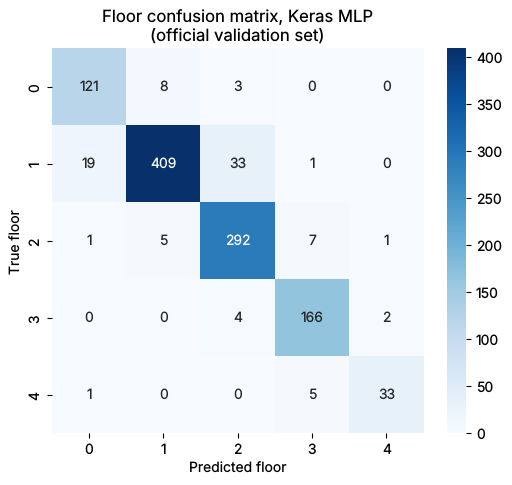

saved figures/floor_confusion_matrix.png


In [19]:
# Floor confusion matrix for the model chosen by group CV.
floor_model = selected["floor"]
cm = confusion_matrix(y_test["floor"], test_predictions[("floor", floor_model)], labels=sorted(y_test["floor"].unique()))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=sorted(y_test["floor"].unique()), yticklabels=sorted(y_test["floor"].unique()))
ax.set_xlabel("Predicted floor")
ax.set_ylabel("True floor")
ax.set_title(f"Floor confusion matrix, {floor_model}\n(official validation set)")
save_and_show(fig, "floor_confusion_matrix.png")

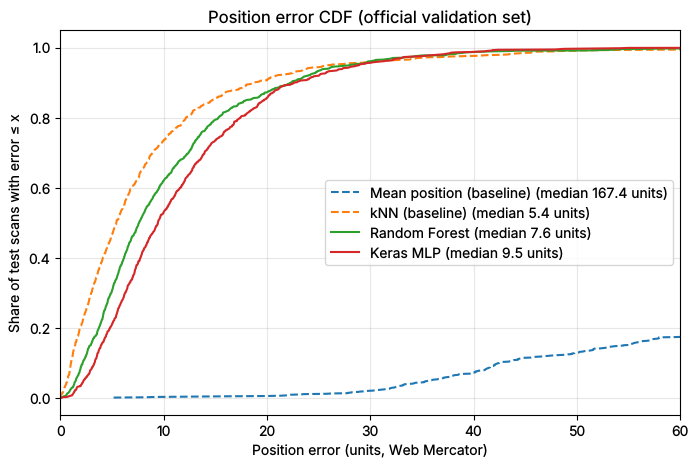

saved figures/position_error_cdf.png


In [20]:
# Cumulative distribution of the 2-D position error.
fig, ax = plt.subplots(figsize=(8, 5))
for (task, model_name), pred in test_predictions.items():
    if task != "position":
        continue
    err = np.sort(position_errors(y_test["position"], pred))
    style = "--" if "baseline" in model_name else "-"
    ax.plot(err, np.arange(1, len(err) + 1) / len(err), style, label=f"{model_name} (median {np.median(err):.1f} units)")
ax.set_xlim(0, 60)
ax.set_xlabel("Position error (units, Web Mercator)")
ax.set_ylabel("Share of test scans with error ≤ x")
ax.set_title("Position error CDF (official validation set)")
ax.grid(alpha=0.3)
ax.legend()
save_and_show(fig, "position_error_cdf.png")

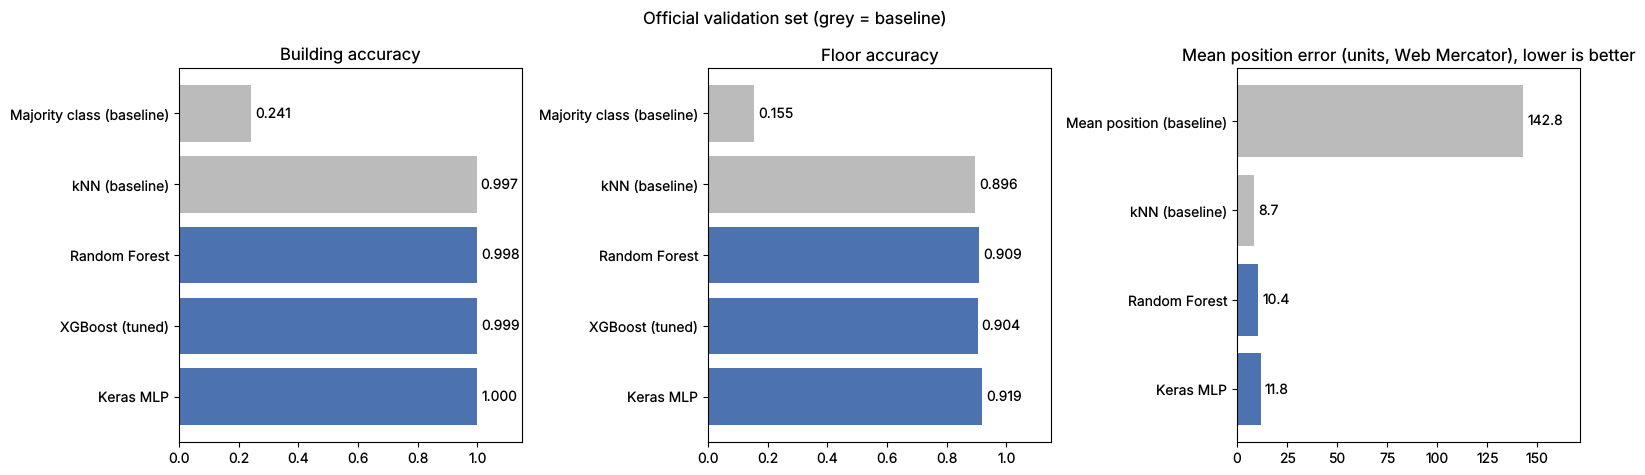

saved figures/model_comparison.png


In [21]:
# Model comparison chart (all numbers from the results table above).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
panels = [("building", "accuracy", "Building accuracy"),
          ("floor", "accuracy (floor hit rate)", "Floor accuracy"),
          ("position", "mean error (units)", "Mean position error (units, Web Mercator), lower is better")]
for ax, (task, col, title) in zip(axes, panels):
    part = results[results["task"] == task]
    colors = ["#bbbbbb" if "baseline" in m else "#4c72b0" for m in part["model"]]
    bars = ax.barh(part["model"], part[col], color=colors)
    ax.bar_label(bars, fmt="%.3f" if task != "position" else "%.1f", padding=3)
    ax.set_title(title)
    ax.invert_yaxis()
    if task != "position":
        ax.set_xlim(0, 1.15)   # room for the value labels next to bars close to 1.0
    else:
        ax.set_xlim(0, part[col].max() * 1.2)
fig.suptitle("Official validation set (grey = baseline)")
fig.tight_layout()
save_and_show(fig, "model_comparison.png")

### 7.2 Error analysis

In [22]:
b_true, f_true = y_test["building"].to_numpy(), y_test["floor"].to_numpy()
f_pred = test_predictions[("floor", floor_model)]
b_pred = test_predictions[("building", selected["building"])]
pos_pred = test_predictions[("position", selected["position"])]
pos_err = position_errors(y_test["position"], pos_pred)

per_building = pd.DataFrame({"building": b_true, "floor_ok": f_pred == f_true, "pos_err": pos_err})
summary = per_building.groupby("building").agg(test_scans=("floor_ok", "size"), floor_accuracy=("floor_ok", "mean"),
                                               median_pos_error_units=("pos_err", "median"), mean_pos_error_units=("pos_err", "mean"))
print(f"Floor model: {floor_model}; building model: {selected['building']}; position model: {selected['position']}\n")
print(summary.round(3).to_string())

wrong = f_pred != f_true
off_by = np.abs(f_pred[wrong] - f_true[wrong])
print(f"\nWrong floor predictions: {wrong.sum()} of {len(f_true)}")
print("How many floors off:", {int(k): int(v) for k, v in zip(*np.unique(off_by, return_counts=True))})
print(f"Building errors ({selected['building']}): {(b_pred != b_true).sum()} of {len(b_true)}")

confusions = pd.Series([f"B{b}: floor {t} -> {p}" for b, t, p in zip(b_true[wrong], f_true[wrong], f_pred[wrong])])
print("\nMost common floor confusions:")
print(confusions.value_counts().head(8).to_string())

Floor model: Keras MLP; building model: XGBoost (tuned); position model: kNN (baseline)

          test_scans  floor_accuracy  median_pos_error_units  mean_pos_error_units
building                                                                          
0                536           0.965                   3.967                 5.855
1                307           0.824                   6.786                10.590
2                268           0.937                   7.524                12.307

Wrong floor predictions: 90 of 1111
How many floors off: {1: 83, 2: 6, 4: 1}
Building errors (XGBoost (tuned)): 1 of 1111

Most common floor confusions:
B1: floor 1 -> 2    27
B1: floor 1 -> 0    15
B0: floor 0 -> 1     5
B2: floor 4 -> 3     5
B1: floor 2 -> 3     4
B0: floor 1 -> 0     4
B0: floor 1 -> 2     4
B2: floor 2 -> 3     3


## 8. What changed from the original version and why

The "original" numbers below are copied from the saved outputs of `01_original_course_version.ipynb`
(random 80/20 split of the training file). The "corrected" numbers are computed in this notebook on the official validation set.

In [23]:
# Numbers copied from the saved outputs of the original course notebook (not re-run).
original = {
    ("building", "Random Forest"): "0.9876 accuracy (random split)",
    ("building", "XGBoost (tuned)"): "0.9865 accuracy (random split, not tuned)",
    ("floor", "Random Forest"): "0.8108 accuracy (random split); 0.6710 in 5-fold CV",
    ("floor", "XGBoost (tuned)"): "0.8072 accuracy (random split); 0.6817 in 5-fold CV",
    ("position", "Random Forest"): "RMSE 0.53 m lat / 0.68 m long - INVALID (leakage)",
    ("position", "Keras MLP"): "RMSE 8.32 m lat / 7.97 m long - INVALID (leakage)",
}
rows = []
for (task, model_name), before in original.items():
    r = results[(results["task"] == task) & (results["model"] == model_name)].iloc[0]
    if task == "position":
        after = f"mean 2-D error {r['mean error (units)']:.2f} units (median {r['median (units)']:.2f} units)"
    elif task == "floor":
        after = f"{r['accuracy (floor hit rate)']:.4f} accuracy, macro-F1 {r['macro-F1']:.4f}"
    else:
        after = f"{r['accuracy']:.4f} accuracy"
    rows.append({"task": task, "model": model_name, "original (course, 2025)": before,
                 "corrected (official validation set)": after})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows)

,task,model,"original (course, 2025)",corrected (official validation set)
0,building,Random Forest,0.9876 accuracy (random split),0.9982 accuracy
1,building,XGBoost (tuned),"0.9865 accuracy (random split, not tuned)",0.9991 accuracy
2,floor,Random Forest,0.8108 accuracy (random split); 0.6710 in 5-fold CV,"0.9091 accuracy, macro-F1 0.8962"
3,floor,XGBoost (tuned),0.8072 accuracy (random split); 0.6817 in 5-fold CV,"0.9037 accuracy, macro-F1 0.8917"
4,position,Random Forest,RMSE 0.53 m lat / 0.68 m long - INVALID (leakage),mean 2-D error 10.43 units (median 7.65 units)
5,position,Keras MLP,RMSE 8.32 m lat / 7.97 m long - INVALID (leakage),mean 2-D error 11.76 units (median 9.45 units)


| Problem in the original | What this notebook does instead |
|---|---|
| Regression used the other coordinate, TIMESTAMP, SPACEID, BUILDINGID, RELATIVEPOSITION as inputs (leakage) | Only WAP columns are inputs; longitude and latitude are predicted together |
| 100 → NaN, 465 of 520 access points dropped, the rest mean/median-imputed | 100 → −105 dBm, all access points that are ever detected are kept, no imputation |
| Random split of the training file; official validation set unused | Group CV on the training file for all choices; official validation set used once per final model |
| No baselines | Majority class, kNN and mean-position baselines |
| GridSearchCV imported but never used | RandomizedSearchCV with group CV for XGBoost (20 candidates for floor, 10 for building); kNN k chosen by group CV |
| Scaler fitted before the split | Fixed RSSI transform inside Pipelines; nothing is fitted on test data |
| Hidden state, markdown text in code cells | Runs top to bottom from a fresh runtime |
| Pie legend swapped; wrong bar in a chart; blank saved PNGs | Correct labels; every chart is built from the results table; figures saved before `plt.show()` |

In [24]:
# Zip the figures folder for easy download from Colab.
archive = shutil.make_archive(str(ROOT / "figures"), "zip", root_dir=FIG_DIR)
print("Created", Path(archive).name, "with:", sorted(p.name for p in FIG_DIR.iterdir()))
print(f"Total run time: {(time.time() - START_TIME) / 60:.1f} minutes")

Created figures.zip with: ['eda_overview.png', 'floor_confusion_matrix.png', 'model_comparison.png', 'position_error_cdf.png']
Total run time: 17.6 minutes
